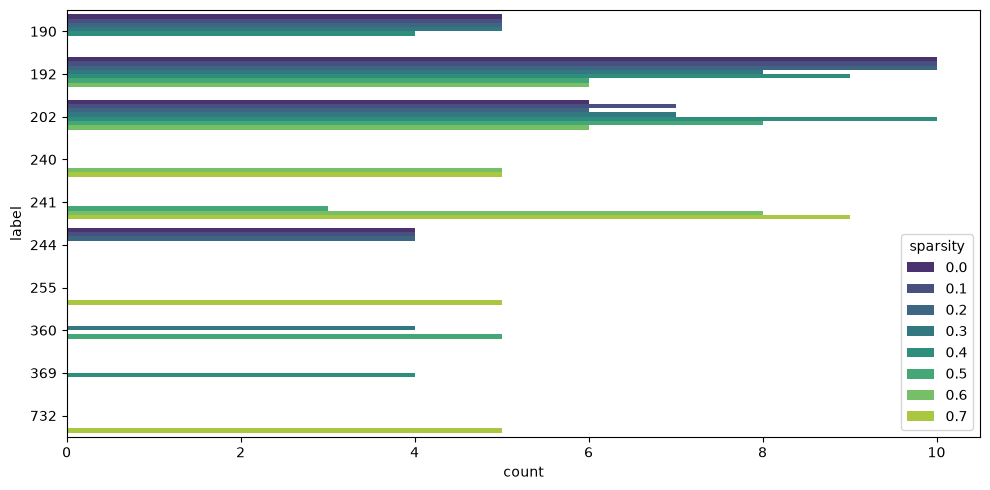

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

prunings = [
'global-unstructured-L1',
   # 'local-unstructured-L1',
]
levels = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
target_class = 104

# ------------------------------------------------------------------
# 1. Collect data
# ------------------------------------------------------------------
data = []
for p in prunings:
   for l in levels:
      df = pd.read_csv(f'./results/negative-similarity/all-minmax-{p}-{l}.csv')
      temp = (
        df[(df['target_class_idx'] == target_class) & (df['order'] <= 4)]
        .sort_values('order')[['order', 'least_class_idx', 'least_class_count']]
        .reset_index(drop=True)
      )
      for _, row in temp.iterrows():
        data.append({
           "sparsity": float(l),
           "label":   int(row["least_class_idx"]),
           "count":   int(row["least_class_count"]),
        })

# ------------------------------------------------------------------
# 2. Build & clean DataFrame
# ------------------------------------------------------------------
df = pd.DataFrame(data)

df["sparsity"] = df["sparsity"].astype(float).round(2).astype(str)  # categorical hue
df["label"]   = df["label"].astype(int).astype(str)
df["count"]   = pd.to_numeric(df["count"], errors="coerce")
df = df.dropna(subset=["sparsity", "label", "count"])

# Collapse duplicate (label, sparsity) rows so each bar is unique
df = df.groupby(["sparsity", "label"], as_index=False)["count"].sum()

# ------------------------------------------------------------------
# 3. Consistent ordering
# ------------------------------------------------------------------
order    = sorted(df["label"].unique(),   key=int)    # numeric label order
hue_order = sorted(df["sparsity"].unique(), key=float)  # numeric sparsity order

# ------------------------------------------------------------------
# 4. Plot
# ------------------------------------------------------------------
plt.figure(figsize=(10, max(4, 0.5 * len(order))))
ax = sns.barplot(
   data=df,
   y="label",
   x="count",
   hue="sparsity",
   order=order,
   hue_order=hue_order,
   orient="h",
   estimator="sum",
   errorbar=None,
   palette="viridis",
)

# ------------------------------------------------------------------
# 5. Legend sanity check + styling
# ------------------------------------------------------------------
handles, labels = ax.get_legend_handles_labels()
plt.tight_layout()

In [ ]:
import torch
import numpy as np
from PIL import Image
from torchvision import transforms, models

# 1. Load pretrained model
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1).eval().cuda()

# 2. Standard ImageNet preprocessing
tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# 3. Load your dog and cat images
img_dog = tf(Image.open("dog.jpg").convert("RGB"))   # [3,224,224]
img_cat = tf(Image.open("cat.jpg").convert("RGB"))

# 4. Linear interpolation + inference
alphas = np.linspace(0, 1, 11)
for a in alphas:
    mixed = (1 - a) * img_dog + a * img_cat          # shape [3,224,224]
    x = mixed.unsqueeze(0).cuda()                     # [1,3,224,224]
    with torch.no_grad():
        logits = model(x)
    probs = logits.softmax(-1)[0]
    top5 = probs.topk(5)
    print(f"alpha={a:.2f}")
    for idx, p in zip(top5.indices, top5.values):
        print(f"  class {idx.item():4d}  prob {p.item():.4f}")